# Masking Comparison

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 07.04.2026
- Date of Last Modification: 14.04.2026 (by Sebastian Birk (sb75@sanger.ac.uk))

=== Data points per (ablation, region_key) ===
region_key         Sub_molecular_tissue_region  ccf_region_name
ablation                                                       
stjepa_v2_03_mask                           27               27
stjepa_v2_04_mask                           27               27
stjepa_v2_05_mask                           27               27
stjepa_v2_06_mask                           27               27
stjepa_v2_07_mask                           27               27
stjepa_v2_08_mask                           27               27
stjepa_v2_09_mask                           27               27

Saved to /nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation/results/niche_identification_masking_ratio_ablations.csv

Saved ablation_masking_ratio_niche_NMI_comparison.svg / .pdf / .png
Saved ablation_masking_ratio_niche_ARI_comparison.svg / .pdf / .png


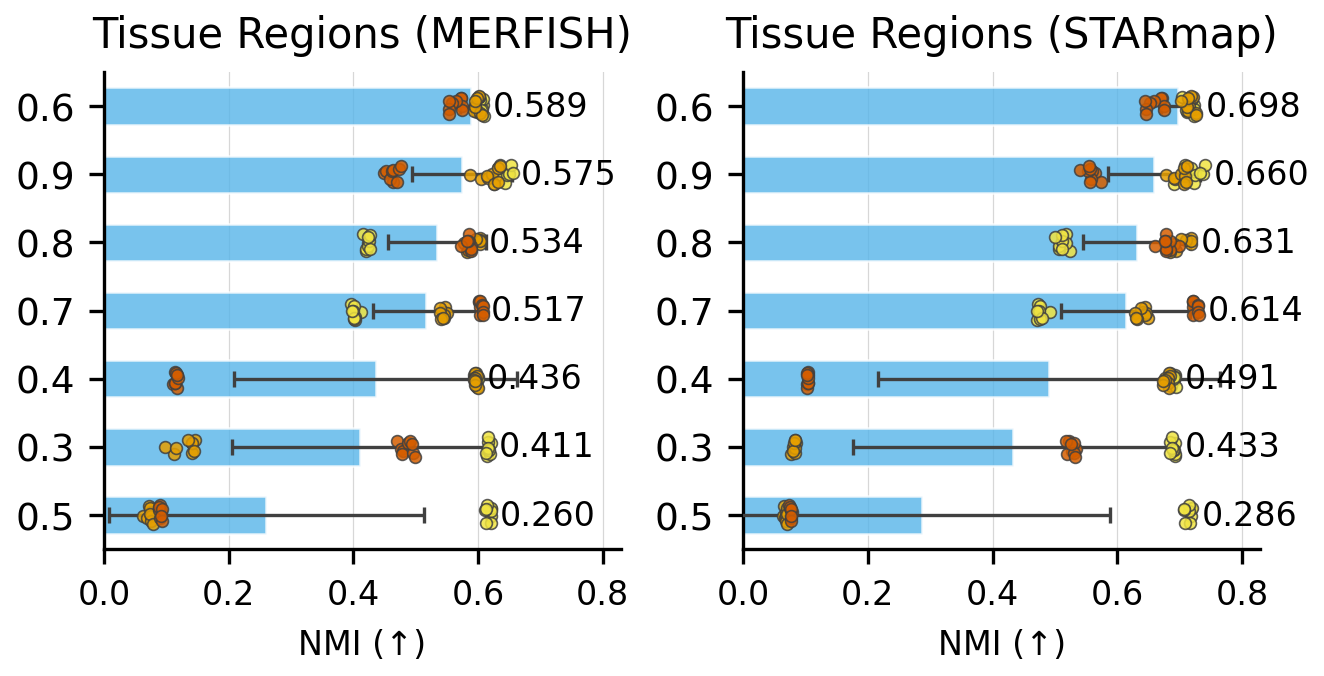

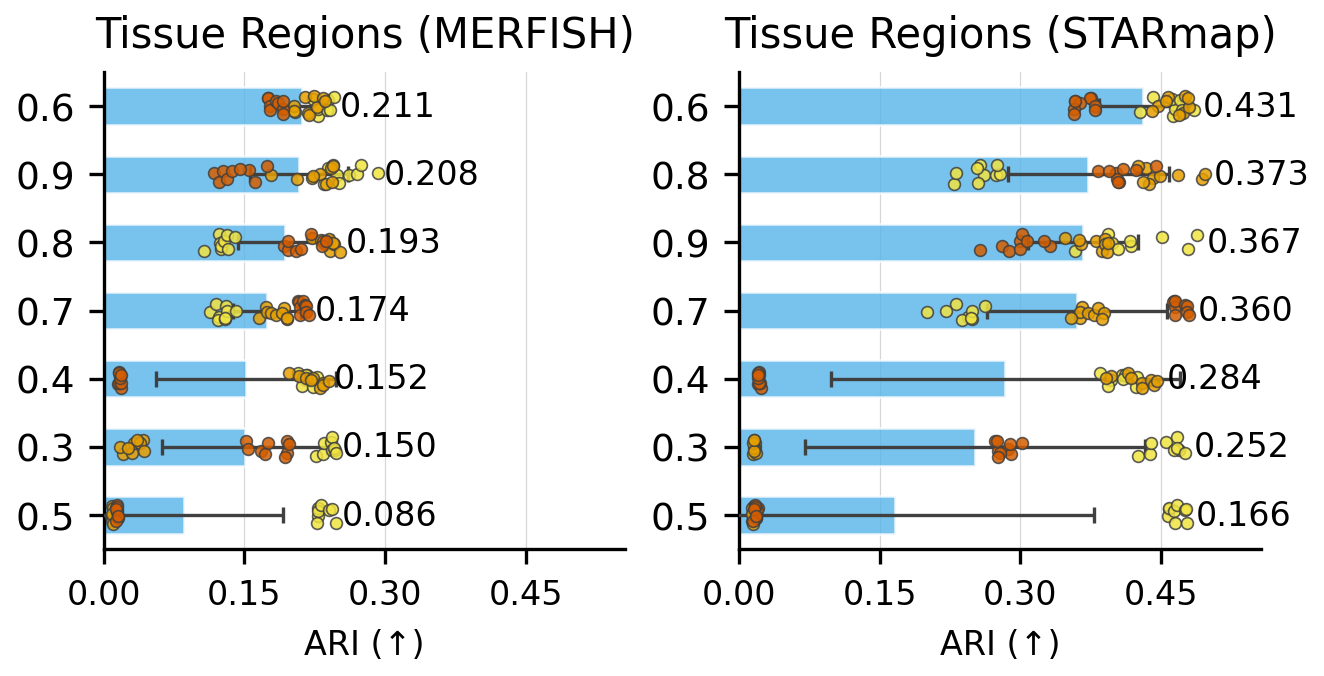


Saved batch integration dataframe to /nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation/results/batch_integration_masking_ratio_ablations.csv
Saved ablation_masking_ratio_batch_integration_iLISI.svg / .pdf / .png
Saved ablation_masking_ratio_batch_integration_ASW.svg / .pdf / .png
Saved ablation_masking_ratio_batch_integration_MMD.svg / .pdf / .png


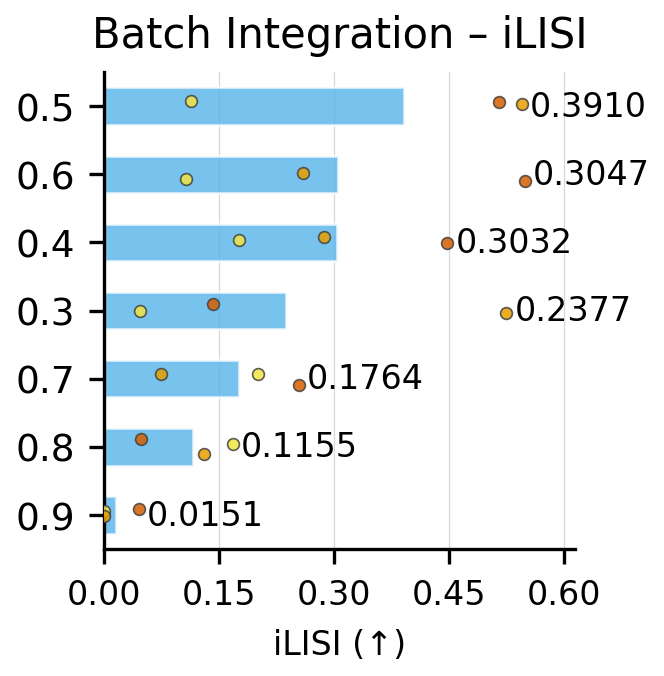

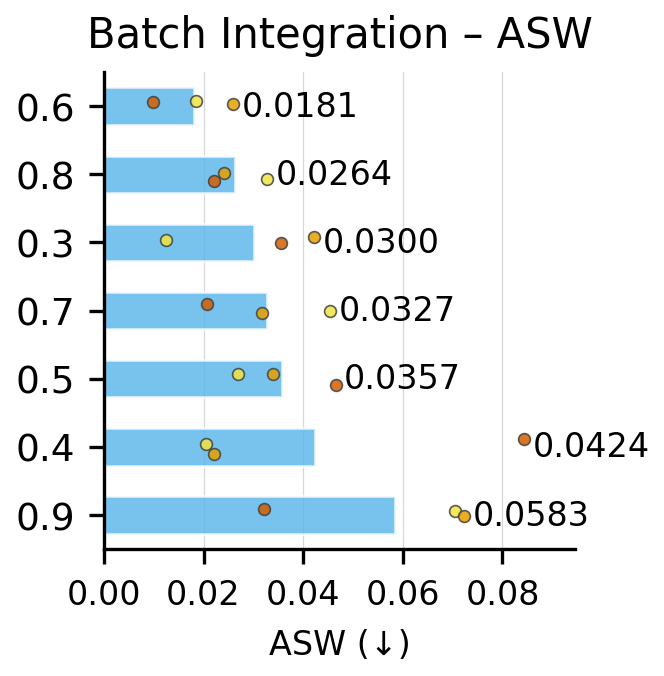

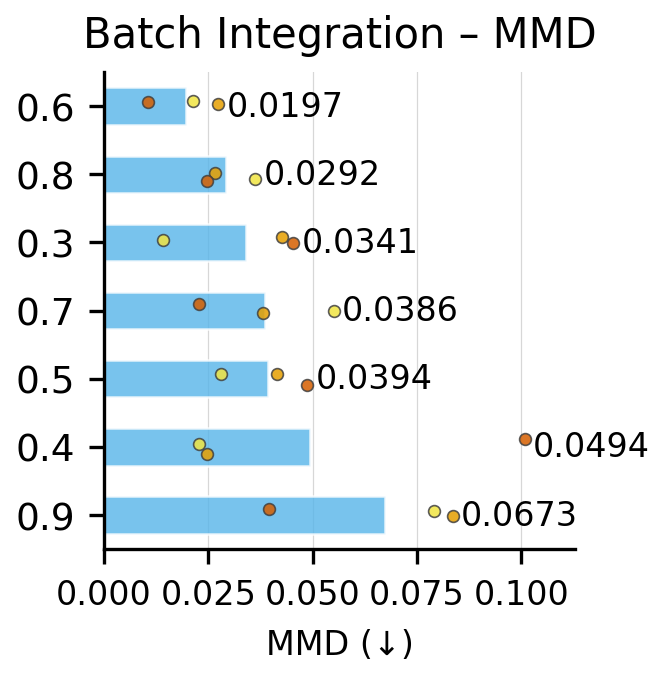

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from pathlib import Path

# ---------------------------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------------------------
ablation_timestamp_pairs = [
    ("stjepa_v2_03_mask", ["10042026_193040_939", "13042026_081820_978", "13042026_081829_476"]),
    ("stjepa_v2_04_mask", ["10042026_193005_683", "13042026_010822_133", "13042026_000907_092"]),
    ("stjepa_v2_05_mask", ["09042026_143419_031", "13042026_021454_332", "13042026_011724_791"]),
    ("stjepa_v2_06_mask", ["21032026_085513_196", "11042026_190115_580", "11042026_202814_332"]),
    ("stjepa_v2_07_mask", ["09042026_115308_738", "13042026_041129_183", "13042026_023554_354"]),
    ("stjepa_v2_08_mask", ["09042026_120745_754", "12042026_083712_309", "12042026_083751_854"]),
    ("stjepa_v2_09_mask", ["09042026_134026_577", "12042026_130417_075", "12042026_083851_341"]),
]

ABLATION_LABELS = {
    "stjepa_v2_03_mask": "0.3",
    "stjepa_v2_04_mask": "0.4",
    "stjepa_v2_05_mask": "0.5",
    "stjepa_v2_06_mask": "0.6",
    "stjepa_v2_07_mask": "0.7",
    "stjepa_v2_08_mask": "0.8",
    "stjepa_v2_09_mask": "0.9",
}

COLOR_MAP = {a: "#56B4E9" for a, _ in ablation_timestamp_pairs}

ablation_order = [a for a, _ in ablation_timestamp_pairs]

DOT_COLORS = ["#F0E442", "#E69F00", "#D55E00"]

base_path = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts/ablation")
results_dir = base_path / "results"
figures_dir = base_path / "figures"
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

REGION_TITLES = {
    "ccf_region_name":             "Tissue Regions (MERFISH)",
    "Sub_molecular_tissue_region": "Tissue Regions (STARmap)",
}
REGION_ORDER = ["ccf_region_name", "Sub_molecular_tissue_region"]

# ---------------------------------------------------------------------------
# 2. Style settings
# ---------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

# ===========================================================================
# PART A: Niche identification
# ===========================================================================

niche_records = []
for ablation, timestamps in ablation_timestamp_pairs:
    for run_idx, timestamp in enumerate(timestamps):
        fpath = (
            base_path / ablation / timestamp
            / "mmb0-1b_smb1-1b_1p_neighborhood_emb_niche_identification_metrics_res_sweep.csv"
        )
        if not fpath.exists():
            print(f"[WARN] File not found, skipping: {fpath}")
            continue
        df = pd.read_csv(fpath)
        df["ablation"] = ablation
        df["run_idx"] = run_idx
        niche_records.append(df)

if not niche_records:
    raise FileNotFoundError("No niche identification CSV files were found.")

df_niche = pd.concat(niche_records, ignore_index=True)

print("=== Data points per (ablation, region_key) ===")
print(df_niche.groupby(["ablation", "region_key"]).size().unstack(fill_value=0))
print()

df_niche.to_csv(results_dir / "niche_identification_masking_ratio_ablations.csv", index=False)
print(f"Saved to {results_dir / 'niche_identification_masking_ratio_ablations.csv'}\n")

def plot_niche_horizontal(df, metric, ablation_order, higher_is_better=True):
    region_keys = REGION_ORDER
    n_panels = len(region_keys)
    n_ab = len(ablation_order)

    fig, axes = plt.subplots(
        1, n_panels,
        figsize=(2.2 * n_panels, 0.22 * n_ab + 0.7),
        sharex=True,
        constrained_layout=True,
    )
    if n_panels == 1:
        axes = [axes]

    for ax, rk in zip(axes, region_keys):
        sub = df[df["region_key"] == rk]

        mean_map = {}
        for a in ablation_order:
            vals = sub.loc[sub["ablation"] == a, metric].values
            mean_map[a] = np.mean(vals) if len(vals) > 0 else 0

        sorted_abs = sorted(
            ablation_order,
            key=lambda a: mean_map[a],
            reverse=not higher_is_better,
        )

        means, sds = [], []
        per_run_vals = []
        for a in sorted_abs:
            all_vals = sub.loc[sub["ablation"] == a, metric].values
            means.append(np.mean(all_vals) if len(all_vals) > 0 else 0)
            sds.append(np.std(all_vals) if len(all_vals) > 0 else 0)
            run_groups = []
            for ri in sorted(sub.loc[sub["ablation"] == a, "run_idx"].unique()):
                rv = sub.loc[(sub["ablation"] == a) & (sub["run_idx"] == ri), metric].values
                run_groups.append((int(ri), rv))
            per_run_vals.append(run_groups)

        y = np.arange(n_ab)

        ax.barh(y, means, height=0.55,
                color=[COLOR_MAP[a] for a in sorted_abs],
                edgecolor="white", linewidth=0.6, alpha=0.80, zorder=2)

        ax.errorbar(means, y, xerr=sds, fmt="none", ecolor="0.25",
                     elinewidth=0.8, capsize=2.0, capthick=0.8, zorder=3)

        rng = np.random.default_rng(42)
        for i, run_groups in enumerate(per_run_vals):
            for ri, vals in run_groups:
                n_pts = len(vals)
                if n_pts == 0:
                    continue
                jitter = rng.uniform(-0.15, 0.15, size=n_pts)
                ax.scatter(vals, np.full(n_pts, i) + jitter,
                           s=8, color=DOT_COLORS[ri % len(DOT_COLORS)],
                           edgecolor="0.25", linewidth=0.4, zorder=4, alpha=0.85)

        all_flat = [v for rg in per_run_vals for _, vals in rg for v in vals]
        x_max = float(np.max(all_flat)) if all_flat else max(means) if means else 1.0
        for i, m in enumerate(means):
            pts = [v for _, vals in per_run_vals[i] for v in vals]
            right = max(pts) if pts else m
            ax.text(max(m, right) + x_max * 0.02, i, f"{m:.3f}",
                    va="center", ha="left", fontsize=8, zorder=5)

        ax.set_title(REGION_TITLES.get(rk, rk), fontweight="medium", fontsize=10)
        ax.set_yticks(y)
        ax.set_yticklabels([ABLATION_LABELS.get(a, a) for a in sorted_abs], fontsize=9)
        ax.set_xlabel(f"{metric} (\u2191)", fontsize=8)
        ax.set_xlim(0, x_max * 1.12)
        ax.set_ylim(-0.5, n_ab - 0.5)
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
        ax.tick_params(axis="x", labelsize=8)
        ax.grid(axis="x", linewidth=0.3, alpha=0.5)

    return fig

for metric in ["NMI", "ARI"]:
    fig = plot_niche_horizontal(df_niche, metric=metric,
                                ablation_order=ablation_order, higher_is_better=True)
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(figures_dir / f"ablation_masking_ratio_niche_{metric}_comparison.{ext}")
    print(f"Saved ablation_masking_ratio_niche_{metric}_comparison.svg / .pdf / .png")

plt.show()

# ===========================================================================
# PART B: Batch integration
# ===========================================================================

BATCH_METRIC_DIRECTION = {
    "iLISI": "\u2191",
    "ASW":   "\u2193",
    "MMD":   "\u2193",
}

records = []
for ablation, timestamps in ablation_timestamp_pairs:
    for run_idx, timestamp in enumerate(timestamps):
        fpath = (
            base_path / ablation / timestamp
            / "mmb0-1b_smb1-1b_1p_neighborhood_emb_batch_integration_metrics.csv"
        )
        if not fpath.exists():
            print(f"[WARN] not found: {fpath}")
            continue
        df = pd.read_csv(fpath)
        for _, row in df.iterrows():
            records.append({
                "ablation": ablation,
                "run_idx": run_idx,
                "metric": row["metric"],
                "score": float(row["score"]),
            })

if not records:
    raise FileNotFoundError("No batch integration CSV files were found.")

df_batch = pd.DataFrame(records)

df_batch.to_csv(results_dir / "batch_integration_masking_ratio_ablations.csv", index=False)
print(f"\nSaved batch integration dataframe to "
      f"{results_dir / 'batch_integration_masking_ratio_ablations.csv'}")

for bm in df_batch["metric"].unique():
    is_higher_better = BATCH_METRIC_DIRECTION.get(bm, "") == "\u2191"
    df_bm = df_batch[df_batch["metric"] == bm]

    mean_per_ab = df_bm.groupby("ablation")["score"].mean().to_dict()

    sorted_abs = sorted(
        [a for a in ablation_order if a in mean_per_ab],
        key=lambda a: mean_per_ab[a],
        reverse=not is_higher_better,
    )
    n = len(sorted_abs)

    fig, ax = plt.subplots(figsize=(2.2, 0.22 * n + 0.7), constrained_layout=True)
    y = np.arange(n)

    bar_vals = [mean_per_ab[a] for a in sorted_abs]
    ax.barh(y, bar_vals, height=0.55,
            color=[COLOR_MAP[a] for a in sorted_abs],
            edgecolor="white", linewidth=0.6, alpha=0.80, zorder=2)

    rng = np.random.default_rng(42)
    rightmost_x = dict(zip(sorted_abs, bar_vals))

    for i, a in enumerate(sorted_abs):
        sub = df_bm[df_bm["ablation"] == a].sort_values("run_idx")
        for _, row in sub.iterrows():
            ri = int(row["run_idx"])
            val = float(row["score"])
            jit = rng.uniform(-0.12, 0.12)
            ax.scatter(val, i + jit,
                       s=8, color=DOT_COLORS[ri % len(DOT_COLORS)],
                       edgecolor="0.25", linewidth=0.4, zorder=4, alpha=0.85)
            if val > rightmost_x[a]:
                rightmost_x[a] = val

    max_right = max(rightmost_x.values())
    gap = max_right * 0.02
    for i, a in enumerate(sorted_abs):
        ax.text(rightmost_x[a] + gap, i, f"{mean_per_ab[a]:.4f}",
                va="center", ha="left", fontsize=8, zorder=5)

    direction = BATCH_METRIC_DIRECTION.get(bm, "")
    ax.set_yticks(y)
    ax.set_yticklabels([ABLATION_LABELS.get(a, a) for a in sorted_abs], fontsize=9)
    ax.set_xlabel(f"{bm} ({direction})" if direction else bm, fontsize=8)
    ax.set_title(f"Batch Integration – {bm}", fontweight="medium", fontsize=10)
    ax.set_xlim(0, max_right * 1.12)
    ax.set_ylim(-0.5, n - 0.5)
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", linewidth=0.3, alpha=0.5)

    for ext in ["svg", "pdf", "png"]:
        fig.savefig(figures_dir / f"ablation_masking_ratio_batch_integration_{bm}.{ext}")
    print(f"Saved ablation_masking_ratio_batch_integration_{bm}.svg / .pdf / .png")

plt.show()